# School timetabling

Sample Middle School, a fictional school, has six classes, twelve teachers, two science labs and
one gym. Every class owes a fixed number of lessons per subject each week. The question is
**which lesson happens at which time**, so that nobody is in two places at once and the week is
still pleasant to teach.

In this notebook you will:

1. describe a school as plain Python dicts,
2. solve it and print the weekly grid of every class and teacher,
3. check the result yourself, without trusting the solver's status,
4. turn a preference into a rule with a constraint assembly,
5. close the gym day by day and find where the timetable stops existing,
6. repair a published timetable after a change, with and without pinned lessons.

Requires Python 3.11+: `pip install optimaru matplotlib`

In [1]:
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Patch, Rectangle

from optimaru import school_timetabling as st
from optimaru.school_timetabling.constraints import Assembly, default_weights

COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
INK, MUTED = "#52514e", "#898781"
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": INK, "axes.titlesize": 12,
    "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False, "xtick.color": MUTED, "ytick.color": MUTED,
    "grid.color": "#e1e0d9", "grid.linewidth": 0.8, "legend.frameon": False, "font.size": 10,
})

## 1. Describe the school

This use case takes one plain dict and returns one plain dict, so a problem can come straight from
a JSON file. Days are integers from `0` (Monday), and periods start at `1`.

| Key | What it holds |
| --- | --- |
| `calendar` | how many periods each weekday has |
| `subjects` | name, the room type it needs, preferred and avoided periods |
| `teachers` | unavailable times, daily, weekly and consecutive limits, requested free days |
| `class_groups` | the classes, with any times they are not in school |
| `rooms` | special rooms by type. Ordinary lessons stay in the class's own room |
| `courses` | one class and subject: teachers (several means team teaching), periods, doubles, daily cap, fixed times |

The week has 29 cells, and every class owes exactly 29 lessons, so each class's grid is full.
Friday's last period is a fixed homeroom for the whole school. Science and art each need one double
period. Music is taught by a part-timer who works Monday to Wednesday, and art by one who does not
work on Mondays.

In [2]:
DAYS = ["Mon", "Tue", "Wed", "Thu", "Fri"]
PERIODS_PER_DAY = {0: 6, 1: 6, 2: 6, 3: 6, 4: 5}
CLASSES = ["1A", "1B", "2A", "2B", "3A", "3B"]
WEEKLY_PERIODS = {"LANG": 5, "MATH": 5, "ENG": 4, "SCI": 4, "HIST": 3, "PE": 3, "MUS": 2, "ART": 2, "HR": 1}
DOUBLE_PERIOD = {"SCI", "ART"}
HOMEROOM_SLOT = {"day": 4, "period": 5}


def subject(id, name, room=None, preferred=(), avoided=()):
    return {"id": id, "name": name, "required_room_type": room,
            "preferred_periods": list(preferred), "avoided_periods": list(avoided)}


def whole_days(*days):
    return [{"day": d, "period": p} for d in days for p in range(1, PERIODS_PER_DAY[d] + 1)]


def teacher(id, name, subject_id, unavailable=(), free_days=()):
    return {"id": id, "name": name, "subject_ids": [subject_id], "unavailable": list(unavailable),
            "max_periods_per_week": 22, "max_periods_per_day": 5, "max_consecutive_periods": 3,
            "preferred_free_days": list(free_days)}


SUBJECTS = [
    subject("LANG", "Language", preferred=[1, 2, 3, 4]),
    subject("MATH", "Math", preferred=[1, 2, 3, 4]),
    subject("ENG", "English"),
    subject("SCI", "Science", room="science lab"),
    subject("HIST", "History"),
    subject("PE", "PE", room="gym", avoided=[1, 5]),  # not first thing, not right after lunch
    subject("MUS", "Music", room="music room"),
    subject("ART", "Art", room="art room"),
    subject("HR", "Homeroom"),
]
TEACHERS = [
    teacher("T01", "Adler", "LANG"),
    teacher("T02", "Brandt", "LANG"),
    teacher("T03", "Costa", "MATH"),
    teacher("T04", "Dorn", "MATH"),
    teacher("T05", "Ellis", "ENG", free_days=[2]),
    teacher("T06", "Frey", "ENG", free_days=[0]),
    teacher("T07", "Grant", "SCI", free_days=[4]),
    teacher("T08", "Hale", "SCI", free_days=[1]),
    teacher("T09", "Ives", "HIST", free_days=[2]),
    teacher("T10", "Jonas", "PE"),
    teacher("T11", "Keller", "MUS", unavailable=whole_days(3, 4)),
    teacher("T12", "Lund", "ART", unavailable=whole_days(0)),
]
ROOMS = [
    {"id": "LAB1", "name": "Lab 1", "room_type": "science lab"},
    {"id": "LAB2", "name": "Lab 2", "room_type": "science lab"},
    {"id": "GYM", "name": "Gym", "room_type": "gym"},
    {"id": "MUSIC", "name": "Music room", "room_type": "music room"},
    {"id": "ART", "name": "Art room", "room_type": "art room"},
]
SHARED = {"HIST": "T09", "PE": "T10", "MUS": "T11", "ART": "T12"}
STAFF = {
    "1A": {"LANG": "T01", "MATH": "T03", "ENG": "T05", "SCI": "T07", "HR": "T01"},
    "1B": {"LANG": "T01", "MATH": "T03", "ENG": "T05", "SCI": "T07", "HR": "T03"},
    "2A": {"LANG": "T01", "MATH": "T03", "ENG": "T06", "SCI": "T07", "HR": "T05"},
    "2B": {"LANG": "T02", "MATH": "T04", "ENG": "T06", "SCI": "T08", "HR": "T06"},
    "3A": {"LANG": "T02", "MATH": "T04", "ENG": "T06", "SCI": "T08", "HR": "T02"},
    "3B": {"LANG": "T02", "MATH": "T04", "ENG": "T05", "SCI": "T08", "HR": "T04"},
}


def make_problem():
    """A fresh problem dict, so that each experiment can change its own copy."""
    courses = []
    for class_id in CLASSES:
        for subject_id, periods in WEEKLY_PERIODS.items():
            double = subject_id in DOUBLE_PERIOD
            courses.append({
                "id": f"{class_id}-{subject_id}", "class_group_id": class_id, "subject_id": subject_id,
                "teacher_ids": [SHARED.get(subject_id) or STAFF[class_id][subject_id]],
                "periods_per_week": periods,
                "block_periods": 2 if double else 0,
                "max_periods_per_day": 2 if double else 1,
                "fixed_slots": [HOMEROOM_SLOT] if subject_id == "HR" else [],
                "forbidden_slots": [],
                "parallel_group": None,
            })
    return {
        "calendar": {"periods_per_day": {str(d): n for d, n in PERIODS_PER_DAY.items()}},
        "subjects": SUBJECTS,
        "teachers": [{**t} for t in TEACHERS],
        "class_groups": [{"id": c, "name": f"Class {c}", "grade": int(c[0]), "unavailable": []} for c in CLASSES],
        "rooms": ROOMS,
        "courses": courses,
    }


problem = make_problem()
print(f"{len(problem['class_groups'])} classes, {len(problem['teachers'])} teachers, "
      f"{len(problem['courses'])} courses, {sum(c['periods_per_week'] for c in problem['courses'])} lessons")

6 classes, 12 teachers, 54 courses, 174 lessons


Each subject keeps one color in every figure of this notebook. Homeroom is gray because it is fixed
and takes no decision. This chart shows the weekly load each teacher starts from.

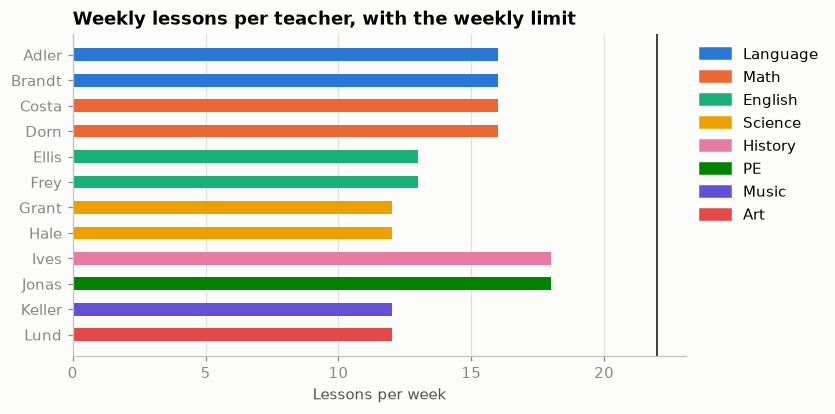

In [3]:
SUBJECT_COLOR = {s["id"]: COLORS[k] for k, s in enumerate(SUBJECTS[:8])} | {"HR": "#c3c2b7"}
SUBJECT_NAME = {s["id"]: s["name"] for s in SUBJECTS}
DARK_TEXT = {"MATH", "ENG", "SCI", "HIST", "HR"}  # subjects whose fill needs ink rather than white

load = Counter(t for c in problem["courses"] for t in c["teacher_ids"] for _ in range(c["periods_per_week"]))
fig, ax = plt.subplots(figsize=(7.2, 3.8))
for row, t in enumerate(TEACHERS):
    ax.barh(row, load[t["id"]], height=0.5, color=SUBJECT_COLOR[t["subject_ids"][0]])
ax.axvline(TEACHERS[0]["max_periods_per_week"], color="#0b0b0b", linewidth=1)
ax.set_yticks(range(len(TEACHERS)), [t["name"] for t in TEACHERS])
ax.invert_yaxis()
ax.set(title="Weekly lessons per teacher, with the weekly limit", xlabel="Lessons per week")
ax.grid(True, axis="x")
ax.legend(handles=[Patch(color=SUBJECT_COLOR[s], label=SUBJECT_NAME[s]) for s in SUBJECT_NAME if s != "HR"],
          loc="upper left", bbox_to_anchor=(1, 1))
plt.show()

## 2. Solve it

`st.solve` returns a new dict and leaves the problem untouched. There is no combined score. The
result reports quality in three fields:

- **`status`**: `FEASIBLE` when no hard rule is broken, `INFEASIBLE` when violations remain at the
  time limit. This is local search, so `INFEASIBLE` is not a proof that no timetable exists.
- **`penalties`**: the raw count of each soft term.
- **`objective_value`**: those counts times their weights. Lower is better, and `0` means no
  penalty at all.

The hard rules: every lesson placed, no class or teacher in two places, unavailable and forbidden
times respected, enough special rooms, daily course caps, double periods adjacent, and the teacher
limits. The soft terms are gaps in a teacher's day, days a teacher comes in, lessons on a requested
free day, gaps in a class's day, and lessons in avoided or non-preferred periods.

In [4]:
TIME_LIMIT = 3
SEED = 1

timetable = st.solve(problem, time_limit_seconds=TIME_LIMIT, random_seed=SEED)

print("status   :", timetable["status"])
print("objective:", timetable["objective_value"])
print("penalties:", timetable["penalties"])
print("notes    :", timetable["notes"])

status   : FEASIBLE
objective: 737.0
penalties: {'teacher_gap': 22, 'teacher_workday': 55, 'teacher_free_day': 3, 'class_gap': 0, 'avoided_period': 6, 'non_preferred_period': 12}
notes    : []


`class_gap` cannot be anything but `0` here: every class has a lesson in all 29 cells, so no class
day can have a hole. Next, where the objective comes from.

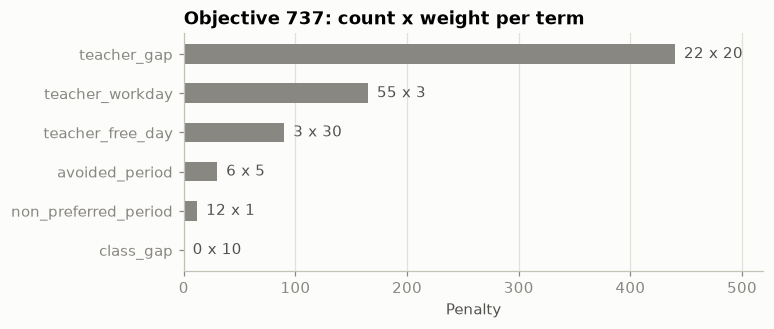

In [5]:
WEIGHTS = default_weights()
terms = sorted(WEIGHTS, key=lambda name: WEIGHTS[name] * timetable["penalties"][name])
costs = [WEIGHTS[name] * timetable["penalties"][name] for name in terms]
assert sum(costs) == timetable["objective_value"]

fig, ax = plt.subplots(figsize=(6.8, 2.8))
ax.barh(terms, costs, height=0.5, color=MUTED)
for row, (name, cost) in enumerate(zip(terms, costs)):
    ax.text(cost + 8, row, f"{timetable['penalties'][name]} x {WEIGHTS[name]}", va="center", color=INK)
ax.set(title=f"Objective {timetable['objective_value']:.0f}: count x weight per term", xlabel="Penalty",
       xlim=(0, max(costs) * 1.18))
ax.grid(True, axis="x")
plt.show()

### The timetable for each class

This is the sheet a school would pin to each classroom wall: days as columns, periods as rows. The
crossed cell is Friday's sixth period, which does not exist.

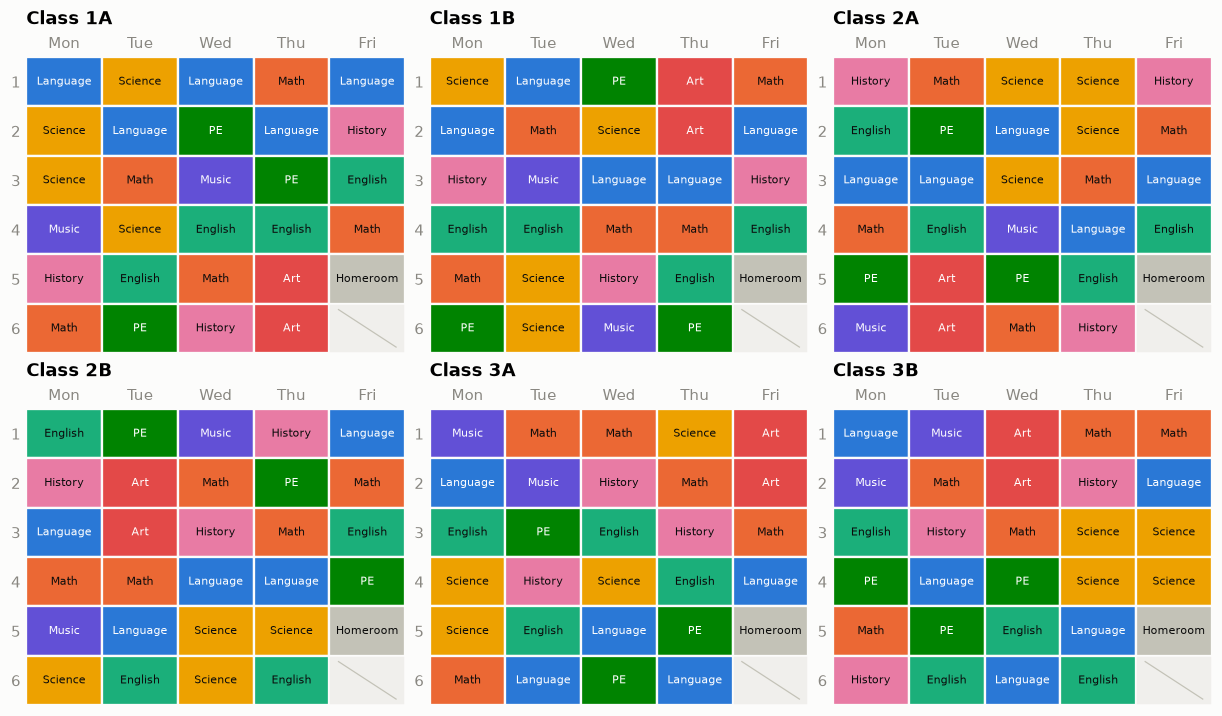

In [6]:
def slot_of(lesson):
    return lesson["slot"]["day"], lesson["slot"]["period"]


def draw_week(ax, cells, title, blocked=()):
    """cells maps (day, period) to (text, subject id). blocked lists cells to shade as unavailable."""
    for day, count in PERIODS_PER_DAY.items():
        for period in range(1, 7):
            if period > count:
                ax.add_patch(Rectangle((day, period - 1), 1, 1, facecolor="#f0efec", edgecolor="#fcfcfb"))
                ax.plot([day + 0.12, day + 0.88], [period - 0.88, period - 0.12], color="#c3c2b7", linewidth=0.8)
                continue
            text, subject_id = cells.get((day, period), ("", None))
            fill = SUBJECT_COLOR[subject_id] if subject_id else "#f0efec"
            if (day, period) in blocked:
                fill = "#d9d8d0"
            ax.add_patch(Rectangle((day, period - 1), 1, 1, facecolor=fill, edgecolor="#fcfcfb", linewidth=1.5))
            if text:
                color = "#0b0b0b" if subject_id in DARK_TEXT else "white"
                ax.text(day + 0.5, period - 0.5, text, ha="center", va="center", fontsize=7.5, color=color)
    ax.set_xlim(0, 5)
    ax.set_ylim(6, 0)
    ax.set_xticks(np.arange(5) + 0.5, DAYS)
    ax.set_yticks(np.arange(6) + 0.5, range(1, 7))
    ax.xaxis.tick_top()
    ax.tick_params(length=0)
    ax.spines[:].set_visible(False)
    ax.set_title(title, pad=8)


fig, axes = plt.subplots(2, 3, figsize=(11, 6.4), layout="constrained")
for ax, class_id in zip(axes.flat, CLASSES):
    cells = {slot_of(x): (SUBJECT_NAME[x["subject_id"]], x["subject_id"])
             for x in timetable["lessons"] if x["class_group_id"] == class_id}
    draw_week(ax, cells, f"Class {class_id}")
plt.show()

### The timetable for each teacher

The same lessons, seen from the staff room. Cells name the class, darker gray cells are times the
teacher is unavailable, and a black frame marks a requested free day. Gaps inside a day are the
`teacher_gap` penalty.

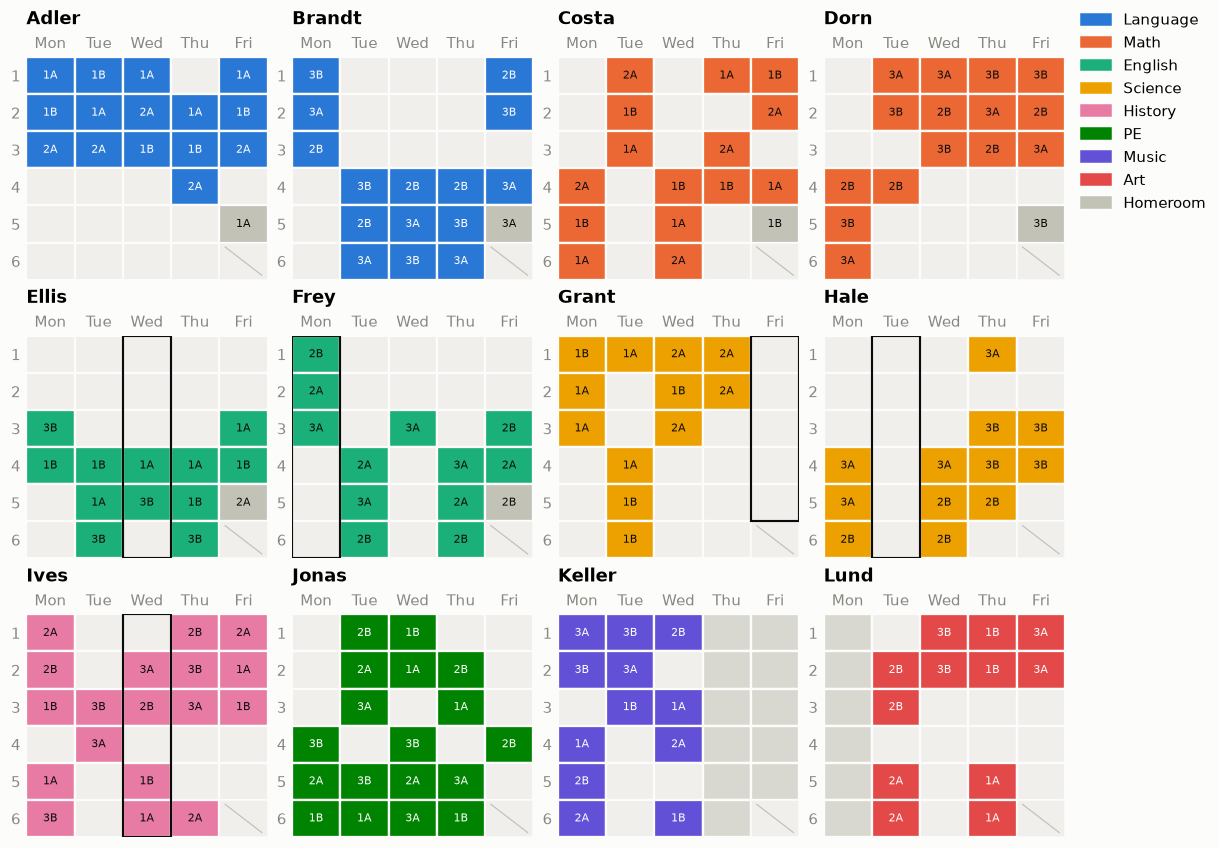

In [7]:
fig, axes = plt.subplots(3, 4, figsize=(11, 7.6), layout="constrained")
for ax, t in zip(axes.flat, TEACHERS):
    cells = {slot_of(x): (x["class_group_id"], x["subject_id"])
             for x in timetable["lessons"] if t["id"] in x["teacher_ids"]}
    blocked = {(s["day"], s["period"]) for s in t["unavailable"]}
    draw_week(ax, cells, t["name"], blocked)
    for day in t["preferred_free_days"]:
        ax.add_patch(Rectangle((day, 0), 1, PERIODS_PER_DAY[day], fill=False, edgecolor="#0b0b0b", linewidth=1.4))
fig.legend(handles=[Patch(color=SUBJECT_COLOR[s], label=SUBJECT_NAME[s]) for s in SUBJECT_NAME],
           loc="outside right upper")
plt.show()

## 3. Check the result yourself

A timetable can be verified from the output alone. This recomputes the hard rules from
`timetable["lessons"]` with no solver code, then recounts two soft terms and compares them with what
the solver reported.

In [8]:
def check_hard_rules(problem, lessons):
    """Number of violations per hard rule, from the lessons and the problem dict only."""
    courses = {c["id"]: c for c in problem["courses"]}
    teachers = {t["id"]: t for t in problem["teachers"]}
    by_teacher, by_class, by_course = {}, {}, {}
    for x in lessons:
        by_class.setdefault(x["class_group_id"], []).append(slot_of(x))
        by_course.setdefault(x["course_id"], []).append(slot_of(x))
        for t in x["teacher_ids"]:
            by_teacher.setdefault(t, []).append(slot_of(x))

    report = Counter()
    for course_id, course in courses.items():
        slots = by_course.get(course_id, [])
        report["periods per week"] += abs(course["periods_per_week"] - len(slots))
        days = Counter(day for day, _ in slots)
        report["course daily cap"] += sum(max(0, n - course["max_periods_per_day"]) for n in days.values())
        fixed = [(s["day"], s["period"]) for s in course["fixed_slots"]]
        report["fixed times"] += sum(s not in slots for s in fixed)
        forbidden = {(s["day"], s["period"]) for s in course["forbidden_slots"]}
        report["forbidden times"] += sum(s in forbidden for s in slots)
        if course["block_periods"] >= 2:
            report["double periods"] += not any((d, p + 1) in slots for d, p in slots)
    for slots in by_class.values():
        report["class double-booked"] += len(slots) - len(set(slots))
    for teacher_id, slots in by_teacher.items():
        t = teachers[teacher_id]
        report["teacher double-booked"] += len(slots) - len(set(slots))
        off = {(s["day"], s["period"]) for s in t["unavailable"]}
        report["teacher unavailable"] += sum(s in off for s in slots)
        report["teacher weekly limit"] += max(0, len(slots) - t["max_periods_per_week"])
        days = Counter(day for day, _ in slots)
        report["teacher daily limit"] += sum(max(0, n - t["max_periods_per_day"]) for n in days.values())
        for day in days:
            run = 0
            for period in range(1, 7):
                run = run + 1 if (day, period) in slots else 0
                report["consecutive limit"] += run > t["max_consecutive_periods"]
    rooms = [(x["room_id"], slot_of(x)) for x in lessons if x["room_id"]]
    report["room double-booked"] = len(rooms) - len(set(rooms))
    needs_room = {s["id"] for s in problem["subjects"] if s["required_room_type"]}
    report["special room missing"] = sum(x["subject_id"] in needs_room and not x["room_id"] for x in lessons)
    return report


def idle_periods(slots):
    """Empty periods between the first and last lesson of each day."""
    idle = 0
    for day in {d for d, _ in slots}:
        periods = [p for d, p in slots if d == day]
        idle += max(periods) - min(periods) + 1 - len(periods)
    return idle


report = check_hard_rules(problem, timetable["lessons"])
for rule, violations in report.items():
    print(f"{rule:24s}{violations}")

gaps = sum(idle_periods([slot_of(x) for x in timetable["lessons"] if t["id"] in x["teacher_ids"]])
           for t in TEACHERS)
days_in = sum(len({slot_of(x)[0] for x in timetable["lessons"] if t["id"] in x["teacher_ids"]})
              for t in TEACHERS)
print(f"\nteacher gaps: recounted {gaps}, reported {timetable['penalties']['teacher_gap']}")
print(f"teacher days: recounted {days_in}, reported {timetable['penalties']['teacher_workday']}")

periods per week        0
course daily cap        0
fixed times             0
forbidden times         0
double periods          0
class double-booked     0
teacher double-booked   0
teacher unavailable     0
teacher weekly limit    0
teacher daily limit     0
consecutive limit       0
room double-booked      0
special room missing    0

teacher gaps: recounted 22, reported 22
teacher days: recounted 55, reported 55


## 4. Turn a preference into a rule

`list_constraints()` names every rule of this use case. `Assembly()` starts from all of them, and
`add` replaces one by name, so a small change stays one line.

In [9]:
for name in st.list_constraints():
    print(name)

unassigned_lesson
class_conflict
teacher_conflict
slot_not_allowed
room_capacity
course_daily_limit
block_adjacency
teacher_load_limit
teacher_consecutive_limit
teacher_gap
teacher_workday
teacher_free_day
class_gap
avoided_period
non_preferred_period


PE is only *avoided* in periods 1 and 5, so the solver may place it there when that saves a gap
somewhere else. Suppose the school now wants that banned outright. `hard=True` moves the rule to the
hard level, and `weight=1` gives it the same price as the other hard rules. Passing `hard=True` alone
keeps the soft weight, which would let it outbid them.

One thing to watch: `status` is computed from the built-in hard rules only. A soft rule you promoted
is not part of it, so read its count in `penalties` instead.

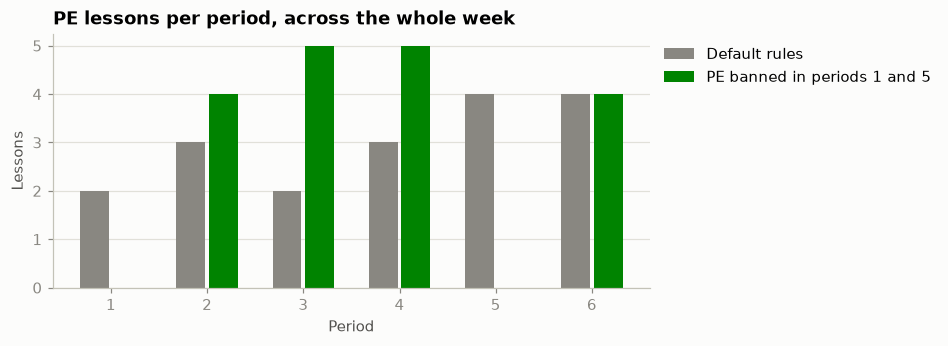

default FEASIBLE  PE in avoided periods 6, teacher gaps 22, off-preference lessons 12
strict  FEASIBLE  PE in avoided periods 0, teacher gaps 25, off-preference lessons 14


In [10]:
strict = st.solve(problem, time_limit_seconds=TIME_LIMIT, random_seed=SEED,
                  constraints=Assembly().add("avoided_period", hard=True, weight=1))


def pe_by_period(result):
    counts = Counter(x["slot"]["period"] for x in result["lessons"] if x["subject_id"] == "PE")
    return [counts[p] for p in range(1, 7)]


periods = np.arange(1, 7)
fig, ax = plt.subplots(figsize=(7, 3))
ax.bar(periods - 0.17, pe_by_period(timetable), width=0.3, color=MUTED, label="Default rules")
ax.bar(periods + 0.17, pe_by_period(strict), width=0.3, color=SUBJECT_COLOR["PE"],
       label="PE banned in periods 1 and 5")
ax.set(title="PE lessons per period, across the whole week", xlabel="Period", ylabel="Lessons")
ax.set_xticks(periods)
ax.grid(True, axis="y")
ax.legend(loc="upper left", bbox_to_anchor=(1, 1))
plt.show()

for label, result in [("default", timetable), ("strict", strict)]:
    p = result["penalties"]
    print(f"{label:8s}{result['status']:10s}PE in avoided periods {p['avoided_period']}, "
          f"teacher gaps {p['teacher_gap']}, off-preference lessons {p['non_preferred_period']}")

Both runs stop on the clock, so a small difference in the other terms can be search noise rather
than the cost of the new rule. The PE count is the part to read: under the hard rule it has to reach `0`.

## 5. Close the gym

There is one gym: six classes owe three PE lessons each, and one teacher runs them all.
Suppose the gym closes on more days of the week. PE courses take the closed days as
`forbidden_slots`.

Counting tells you where this must fail, before any solve. PE can only run in the periods the gym is
open, excluding the Friday homeroom, and Jonas can teach at most five periods a day. If that total
falls below the PE lessons owed, no timetable exists, however long the search runs.

`compute_breakdown` scores any set of lessons against the hard rules, which also tells you how far
from feasible an `INFEASIBLE` result is. Each case runs with three seeds, and every dot is one run.

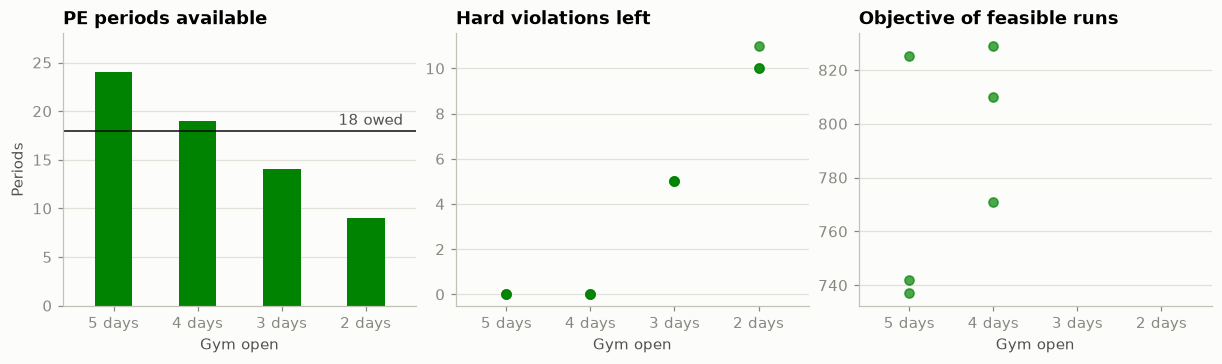

gym open 5 days: capacity 24 of 18 owed, hard violations per seed [0, 0, 0]
gym open 4 days: capacity 19 of 18 owed, hard violations per seed [0, 0, 0]
gym open 3 days: capacity 14 of 18 owed, hard violations per seed [5, 5, 5]
gym open 2 days: capacity  9 of 18 owed, hard violations per seed [10, 10, 11]


In [11]:
def gym_closed(days):
    problem = make_problem()
    for course in problem["courses"]:
        if course["subject_id"] == "PE":
            course["forbidden_slots"] = whole_days(*days)
    return problem


def hard_violations(problem, result):
    converted = st.convert_problem(problem)
    st.inject_solution(converted, result["lessons"])
    return st.canon.compute_breakdown(converted.table).hard_total()


def pe_capacity(closed):
    jonas = TEACHERS[9]
    cells = {d: n - (d == HOMEROOM_SLOT["day"]) for d, n in PERIODS_PER_DAY.items() if d not in closed}
    return sum(min(n, jonas["max_periods_per_day"]) for n in cells.values())


PE_OWED = len(CLASSES) * WEEKLY_PERIODS["PE"]
scenarios = [list(range(k)) for k in range(4)]  # closed: none, Mon, Mon-Tue, Mon-Wed
runs = []
for closed in scenarios:
    case = gym_closed(closed)
    results = [st.solve(case, time_limit_seconds=1, random_seed=seed) for seed in (1, 2, 3)]
    runs.append([(hard_violations(case, r), r["objective_value"]) for r in results])

x = np.arange(len(scenarios))
labels = [f"{5 - len(closed)} days" for closed in scenarios]
fig, axes = plt.subplots(1, 3, figsize=(11, 3.2), layout="constrained")

axes[0].bar(x, [pe_capacity(closed) for closed in scenarios], width=0.45, color=SUBJECT_COLOR["PE"])
axes[0].axhline(PE_OWED, color="#0b0b0b", linewidth=1)
axes[0].text(len(scenarios) - 0.55, PE_OWED + 0.6, f"{PE_OWED} owed", ha="right", color=INK)
axes[0].set(title="PE periods available", ylabel="Periods", ylim=(0, 28))

for k, case in enumerate(runs):
    axes[1].scatter([k] * len(case), [hard for hard, _ in case], s=36, color=SUBJECT_COLOR["PE"], alpha=0.7)
    feasible = [objective for hard, objective in case if hard == 0]
    axes[2].scatter([k] * len(feasible), feasible, s=36, color=SUBJECT_COLOR["PE"], alpha=0.7)
axes[1].set(title="Hard violations left", ylim=(-0.5, None))
axes[2].set(title="Objective of feasible runs")
for ax in axes:
    ax.set_xticks(x, labels)
    ax.set_xlim(-0.6, len(scenarios) - 0.4)
    ax.set_xlabel("Gym open")
    ax.grid(True, axis="y")
plt.show()

for closed, case in zip(scenarios, runs):
    print(f"gym open {5 - len(closed)} days: capacity {pe_capacity(closed):2d} of {PE_OWED} owed, "
          f"hard violations per seed {[hard for hard, _ in case]}")

Where the capacity bar stays under the line, the infeasibility comes from the count above and not
from the search. An empty column in the right-hand chart means no run of that case was feasible.

## 6. Repair a published timetable

Mid-year, Frey takes on another duty that clashes with every English lesson on Frey's busiest day.
`initial_solution` starts the search from an existing timetable. A time that is no longer allowed is
accepted as a hard violation, so the search can repair it. With `time_limit_seconds=0` you get the old
timetable back, scored against the new rule.

In [12]:
frey_lessons = [x for x in timetable["lessons"] if "T06" in x["teacher_ids"] and x["subject_id"] != "HR"]
busiest_day = Counter(x["slot"]["day"] for x in frey_lessons).most_common(1)[0][0]
frey_blocked = [x["slot"] for x in frey_lessons if x["slot"]["day"] == busiest_day]


def frey_change():
    problem = make_problem()
    frey = next(t for t in problem["teachers"] if t["id"] == "T06")
    frey["unavailable"] = frey_blocked
    return problem


def lessons_moved(before, after):
    def placed(result):
        return {(x["course_id"], slot_of(x)) for x in result["lessons"]}
    return len(placed(before) - placed(after))


unchanged = st.solve(frey_change(), time_limit_seconds=0, initial_solution=timetable)
print(f"Frey loses {len(frey_blocked)} periods on {DAYS[busiest_day]}")
print("the old timetable under the new rule:", unchanged["status"], unchanged["notes"])

Frey loses 3 periods on Thu
the old timetable under the new rule: INFEASIBLE ['hard violations left: 3']


A warm start does not promise a similar timetable. The search may move any lesson that is not fixed,
so teachers and families can still get a very different week. When stability matters, pin what must
stay: copy its times into `fixed_slots`, and the engine never moves those lessons.

Below, the classes Frey does not teach keep their published times. Courses with a double period are
left free, because a fully fixed course only keeps its double period when the double falls last in
(day, period) order. The three strategies are compared on what changed and on what they cost.

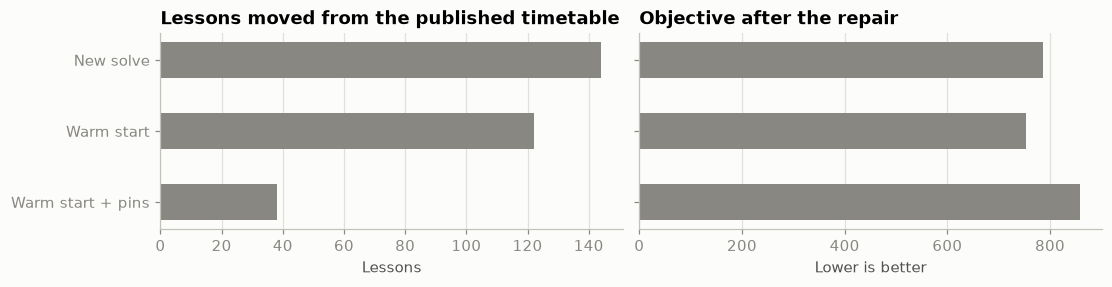

New solve         FEASIBLE   objective 787, moved 144, broken hard rules 0
Warm start        FEASIBLE   objective 753, moved 122, broken hard rules 0
Warm start + pins FEASIBLE   objective 858, moved 38, broken hard rules 0


In [13]:
frey_classes = {c["class_group_id"] for c in make_problem()["courses"] if "T06" in c["teacher_ids"]}


def pinned_change():
    problem = frey_change()
    for course in problem["courses"]:
        if course["class_group_id"] not in frey_classes and not course["block_periods"]:
            course["fixed_slots"] = [x["slot"] for x in timetable["lessons"] if x["course_id"] == course["id"]]
    return problem


repairs = {
    "New solve": st.solve(frey_change(), time_limit_seconds=2, random_seed=11),
    "Warm start": st.solve(frey_change(), time_limit_seconds=2, random_seed=11, initial_solution=timetable),
    "Warm start + pins": st.solve(pinned_change(), time_limit_seconds=2, random_seed=11,
                                  initial_solution=timetable),
}
names = list(repairs)
fig, axes = plt.subplots(1, 2, figsize=(10, 2.5), sharey=True, layout="constrained")
axes[0].barh(names, [lessons_moved(timetable, r) for r in repairs.values()], height=0.5, color=MUTED)
axes[0].set(title="Lessons moved from the published timetable", xlabel="Lessons")
axes[1].barh(names, [r["objective_value"] for r in repairs.values()], height=0.5, color=MUTED)
axes[1].set(title="Objective after the repair", xlabel="Lower is better")
axes[0].invert_yaxis()
for ax in axes:
    ax.grid(True, axis="x")
plt.show()

for name, result in repairs.items():
    print(f"{name:18s}{result['status']:11s}objective {result['objective_value']:.0f}, "
          f"moved {lessons_moved(timetable, result)}, broken hard rules "
          f"{sum(check_hard_rules(frey_change(), result['lessons']).values())}")

### Keep improving a timetable

You can also spend more time on a result by restarting from it in short rounds. **Give each round its
own `random_seed`.** The same start with the same seed repeats the same search. A same-seed round can
still improve while its start differs from the round before, but once a round finds nothing, it
hands back its own start and every later round is the same search again. A longer run with one seed
can stall in the same way, while another seed still finds an improvement.

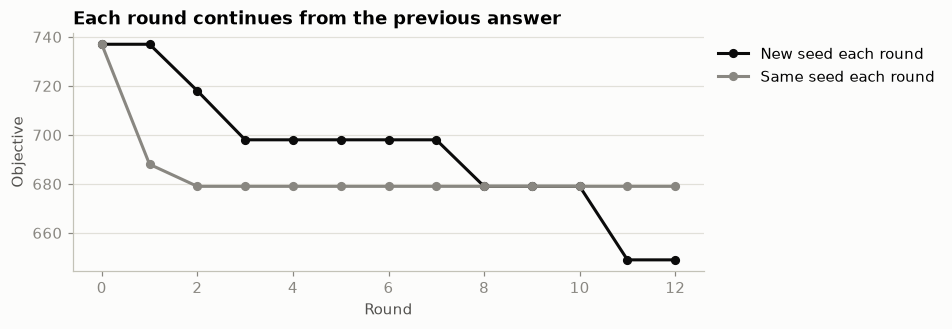

new seed : [737.0, 737.0, 718.0, 698.0, 698.0, 698.0, 698.0, 698.0, 679.0, 679.0, 679.0, 649.0, 649.0]
same seed: [737.0, 688.0, 679.0, 679.0, 679.0, 679.0, 679.0, 679.0, 679.0, 679.0, 679.0, 679.0, 679.0]
lessons moved by one more same-seed round: 0


In [14]:
def rounds(seeds):
    result, history = timetable, [timetable["objective_value"]]
    for seed in seeds:
        result = st.solve(problem, time_limit_seconds=0.5, random_seed=seed, initial_solution=result)
        history.append(result["objective_value"])
    return result, history


_, new_seeds = rounds(range(2, 14))
settled, same_seed = rounds([SEED] * 12)
repeat = st.solve(problem, time_limit_seconds=0.5, random_seed=SEED, initial_solution=settled)

fig, ax = plt.subplots(figsize=(7.4, 2.8))
ax.plot(new_seeds, color="#0b0b0b", linewidth=2, marker="o", markersize=5, label="New seed each round")
ax.plot(same_seed, color=MUTED, linewidth=2, marker="o", markersize=5, label="Same seed each round")
ax.set(title="Each round continues from the previous answer", xlabel="Round", ylabel="Objective")
ax.grid(True, axis="y")
ax.legend(loc="upper left", bbox_to_anchor=(1, 1))
plt.show()

print("new seed :", new_seeds)
print("same seed:", same_seed)
print("lessons moved by one more same-seed round:", lessons_moved(settled, repeat))

A new-seed round can also end level with the one before: that seed found nothing better in its time,
and the best timetable so far is kept. These objectives are the best found in the time limit, not
proven optima.

## Next steps

- Courses also take `parallel_group`, for sections of one class that run at the same time, and several
  `teacher_ids` for team teaching.
- `use-cases/school-timetabling/README.md` covers solver options and how to add moves and constraints in C++.
- For placing talks into rooms and time slots, see `conference-scheduling.ipynb`.